# Track B: On-time delivery risk classifier (Issue #9)
**Target:** `delivered_on_time` (1 = `transit_days <= promised_days`, 0 = late). **Positive class = 1 (on time)**, about 73% of shipments; late (0) is the 27% minority.
**Leakage control:** `transit_days` (realized outcome) and `delivered_on_time` are never used as features. Only ship-time columns are used. Cleaning and the date-boundary split follow the team's Issue #4 fix. Preprocessing is fit on the training part only.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
SEED=42
path = "../data/" if os.path.exists("../data/train.csv") else "data/"
train = pd.read_csv("/content/train.csv", dtype={"origin_zip":str,"dest_zip":str})
print(train.shape, train["delivered_on_time"].value_counts(normalize=True).round(3).to_dict())

(40030, 33) {1: 0.732, 0: 0.268}


## 1. Cleaning (same steps as Issue #4 notebook) and date-boundary split

In [2]:
carriers=["Falcon Post","Northstar Parcel","Summit Express","Ironclad Freight","Vela Freight","Cobalt Regional"]
services=["Ground","Expedited","TwoDay","Overnight","LTL Standard","LTL Guaranteed"]
train["carrier"]=train["carrier"].str.strip().str.lower().map({n.lower():n for n in carriers})
train["service_level"]=train["service_level"].str.strip().str.lower().map({n.lower():n for n in services})
for c in ["origin_zip","dest_zip"]: train[c]=train[c].str.strip().str.zfill(5)
train["order_date"]=pd.to_datetime(train["order_date"]); train["ship_date"]=pd.to_datetime(train["ship_date"])
train=train.drop_duplicates().reset_index(drop=True)
train.loc[train["weight_lbs"]==0,"weight_lbs"]=np.nan
g=((train.shipment_mode=="parcel")&(train.weight_lbs>150))|((train.shipment_mode=="ltl_freight")&(train.weight_lbs>20000))
train.loc[g,"weight_lbs"]/=453.592
print("rows after de-dupe:",len(train), "| unmapped carrier/service:", train.carrier.isna().sum(), train.service_level.isna().sum())

train=train.sort_values("ship_date").reset_index(drop=True)
split_date=train["ship_date"].quantile(0.8,interpolation="nearest").normalize()
tr=train[train.ship_date<split_date].copy(); val=train[train.ship_date>=split_date].copy()
assert tr.ship_date.max()<val.ship_date.min()
print("split date",split_date.date(),"| train",len(tr),"| val",len(val))
print("late rate train/val:",round(1-tr.delivered_on_time.mean(),3),round(1-val.delivered_on_time.mean(),3))

rows after de-dupe: 39949 | unmapped carrier/service: 0 0
split date 2025-08-05 | train 31953 | val 7996
late rate train/val: 0.261 0.296


## 2. Features (ship-time only) and preprocessing

In [3]:
for d in (tr,val): d["lead_days"]=(d.ship_date-d.order_date).dt.days
num=["distance_miles","zone","weight_lbs","length_in","width_in","height_in","pallet_count","residential_flag",
     "signature_required","declared_value_usd","fuel_surcharge_pct","weather_severity","carrier_congestion_index",
     "promised_days","carrier_cost_usd","ship_dow","ship_month","lead_days"]
cat=["shipment_mode","carrier","service_level","origin_metro","dest_metro"]
LEAK={"transit_days","delivered_on_time"}; assert not LEAK&set(num+cat)
Xtr,Xva=tr[num+cat],val[num+cat]; ytr,yva=tr.delivered_on_time.values,val.delivered_on_time.values
def pre(scale):
    n=[("imp",SimpleImputer(strategy="median"))]+([("sc",StandardScaler())] if scale else [])
    return ColumnTransformer([("num",Pipeline(n),num),("cat",OneHotEncoder(handle_unknown="ignore"),cat)])
models={"Dummy (stratified)":Pipeline([("p",pre(False)),("m",DummyClassifier(strategy="stratified",random_state=SEED))]),
 "Logistic Regression":Pipeline([("p",pre(True)),("m",LogisticRegression(class_weight="balanced",max_iter=2000,random_state=SEED))]),
 "Random Forest":Pipeline([("p",pre(False)),("m",RandomForestClassifier(n_estimators=300,min_samples_leaf=5,class_weight="balanced",n_jobs=-1,random_state=SEED))])}
# Pipelines fit preprocessing on training rows only; validation is only transformed.
for m in models.values(): m.fit(Xtr,ytr)

## 3. Evaluation (validation set, threshold 0.5; ROC-AUC and PR-AUC use predicted probabilities)

In [4]:
rows,probs={},{}
for k,m in models.items():
    p=m.predict_proba(Xva)[:,1]; yh=(p>=0.5).astype(int); probs[k]=p
    rows[k]=dict(ROC_AUC=roc_auc_score(yva,p),PR_AUC=average_precision_score(yva,p),
      precision=precision_score(yva,yh,zero_division=0),recall=recall_score(yva,yh),F1=f1_score(yva,yh))
res=pd.DataFrame(rows).T.round(4); print("Positive class = on time (1). Baseline PR-AUC ~ on-time rate =",round(yva.mean(),3)); res

Positive class = on time (1). Baseline PR-AUC ~ on-time rate = 0.704


,ROC_AUC,PR_AUC,precision,recall,F1
Dummy (stratified),0.5006,0.7038,0.7039,0.7467,0.7247
Logistic Regression,0.8841,0.9457,0.9248,0.7480,0.8270
Random Forest,0.8917,0.9489,0.9082,0.8157,0.8594


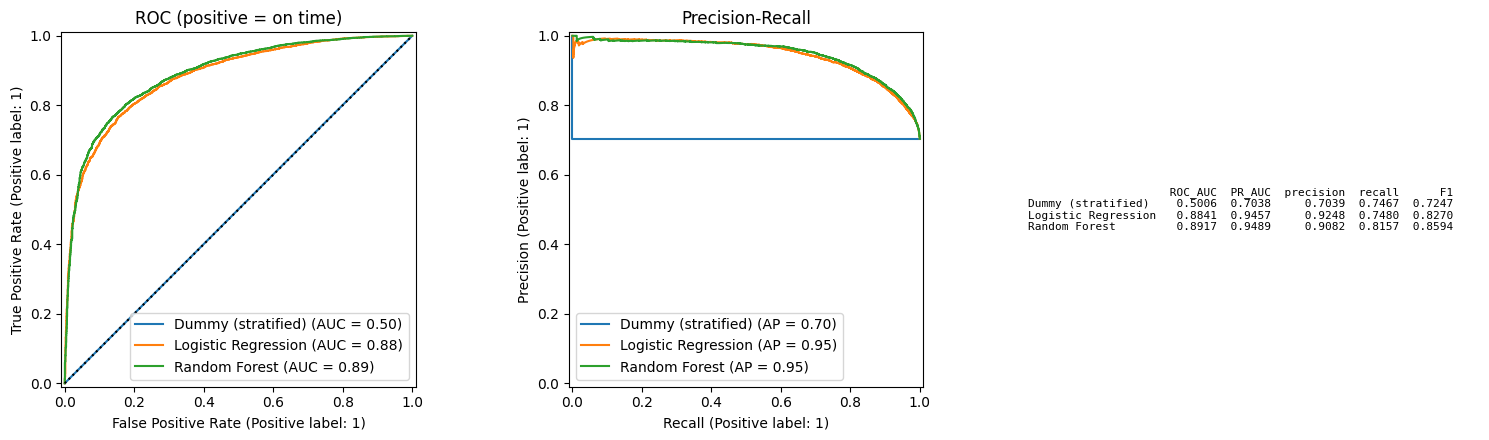

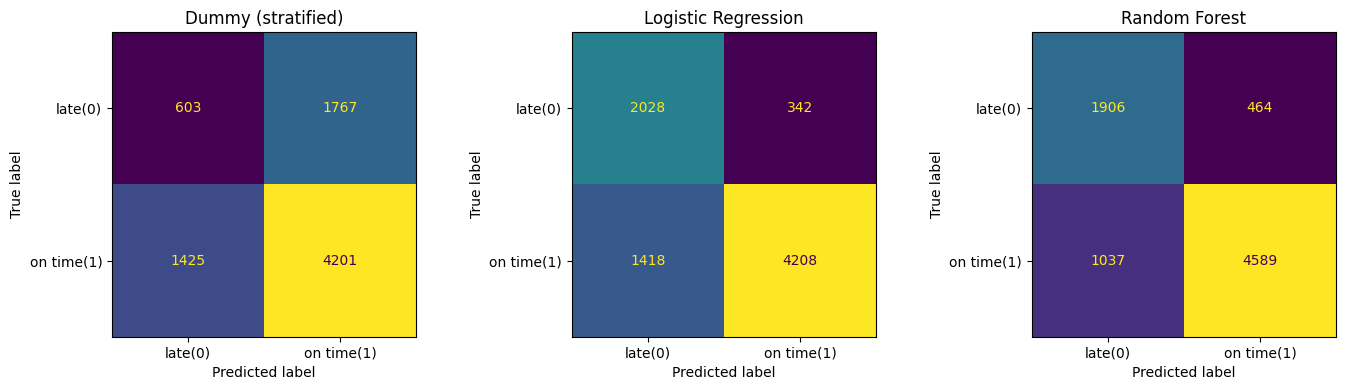

In [5]:
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for k in models:
    RocCurveDisplay.from_predictions(yva,probs[k],name=k,ax=ax[0]); PrecisionRecallDisplay.from_predictions(yva,probs[k],name=k,ax=ax[1])
ax[0].plot([0,1],[0,1],"k:"); ax[0].set_title("ROC (positive = on time)"); ax[1].set_title("Precision-Recall")
ax[2].axis("off"); ax[2].text(0,.5,res.to_string(),family="monospace",fontsize=8,va="center")
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,3,figsize=(14,4))
for a,k in zip(ax,models):
    ConfusionMatrixDisplay(confusion_matrix(yva,(probs[k]>=0.5).astype(int)),display_labels=["late(0)","on time(1)"]).plot(ax=a,colorbar=False); a.set_title(k)
plt.tight_layout(); plt.show()

## 4. Results and usage
See the metrics table above (generated by this notebook, nothing hard-coded). Run all cells from the `notebooks/` folder or repo root; needs `pandas, scikit-learn, matplotlib`. Random seed is 42. The default threshold of 0.5 is used; adjust it on the probabilities (`probs[...]`) if the business cost of missing a late shipment differs. No hyperparameter search was run.

#Late Delivery Evaluation

##Objective

Evaluate how well the existing classifiers identify shipments that are arriving late.

Using precision, recallm F1-score, and PR-AUC with late deliveries as positive class

In [6]:
yva_late = (yva == 0).astype(int) #flip

print("Late shipments:", yva_late.sum()) #tells us how many shipments arrived late
print("Total shipments:", len(yva_late)) #len is short for length. We get the length of late shipments(How many items in something)

Late shipments: 2370
Total shipments: 7996


In [8]:
late_probs = {}

for name, probabilities in probs.items():
  late_probs[name] = 1 - probabilities

In [12]:
rf_late_predictions = (late_probs["Random Forest"] >= 0.5).astype(int)

rf_precision = precision_score(yva_late, rf_late_predictions)
rf_recall = recall_score(yva_late, rf_late_predictions)

print("Late delivery precision:", rf_precision)
print("Late delivery recall:", rf_recall)

Late delivery precision: 0.6476384641522256
Late delivery recall: 0.8042194092827004


In [13]:
rf_f1 = f1_score(yva_late, rf_late_predictions)
print("Late delivery score F1:", rf_f1)

Late delivery score F1: 0.7174854131375871


In [14]:
rf_ap = average_precision_score(yva_late, late_probs["Random Forest"])

print("Late-delivery Average Precision:", rf_ap)

Late-delivery Average Precision: 0.7745391335413359


In [15]:
lr_late_predictions = (late_probs["Logistic Regression"] >= 0.5).astype(int)

lr_precision = precision_score(yva_late, lr_late_predictions)
lr_recall = recall_score(yva_late, lr_late_predictions)

print("Late delivery precision:", lr_precision)
print("Late delivery recall:", lr_recall)

Late delivery precision: 0.5885084155542658
Late delivery recall: 0.8556962025316456


In [16]:
lr_f1 = f1_score(yva_late, lr_late_predictions)
print("Late delivery score F1:", lr_f1)

Late delivery score F1: 0.6973865199449794


In [17]:
lr_ap = average_precision_score(yva_late, late_probs["Logistic Regression"])

print("Late-delivery Average Precision:", lr_ap)

Late-delivery Average Precision: 0.7588313701790524


In [19]:
dm_late_predictions = (late_probs["Dummy (stratified)"] >= 0.5).astype(int)

dm_precision = precision_score(yva_late, dm_late_predictions)
dm_recall = recall_score(yva_late, dm_late_predictions)

print("Late delivery precision:", dm_precision)
print("Late delivery recall:", dm_recall)

Late delivery precision: 0.2973372781065089
Late delivery recall: 0.25443037974683547


In [20]:
dm_f1 = f1_score(yva_late, dm_late_predictions)
print("Late delivery score F1:", dm_f1)

Late delivery score F1: 0.2742155525238745


In [21]:
dm_ap = average_precision_score(yva_late, late_probs["Dummy (stratified)"])

print("Late delivery Average Precision:", dm_ap)

Late delivery Average Precision: 0.29663712932790265


##Testing different Thresholds

Random Forest

In [22]:
rf_predictions_04 = (late_probs["Random Forest"] >= 0.4).astype(int)

rf_precision_04 = precision_score(yva_late, rf_predictions_04)
rf_recall_04 = recall_score(yva_late, rf_predictions_04)
rf_f1_04 = f1_score(yva_late, rf_predictions_04)

print("Precision at 0.4:", rf_precision_04)
print("Recall at 0.4:", rf_recall_04)
print("F1-score at 0.4:", rf_f1_04)

Precision at 0.4: 0.5945714285714285
Recall at 0.4: 0.8780590717299578
F1-score at 0.4: 0.7090289608177172


In [23]:
rf_predictions_03 = (late_probs["Random Forest"] >= 0.3).astype(int)

rf_precision_03 = precision_score(yva_late, rf_predictions_03)
rf_recall_03 = recall_score(yva_late, rf_predictions_03)
rf_f1_03 = f1_score(yva_late, rf_predictions_03)

print("Precision at 0.3:", rf_precision_03)
print("Recall at 0.3:", rf_recall_03)
print("F1-score at 0.3:", rf_f1_03)

Precision at 0.3: 0.5303827751196172
Recall at 0.3: 0.9354430379746835
F1-score at 0.3: 0.6769465648854962


In [24]:
rf_predictions_06 = (late_probs["Random Forest"] >= 0.6).astype(int)

rf_precision_06 = precision_score(yva_late, rf_predictions_06)
rf_recall_06 = recall_score(yva_late, rf_predictions_06)
rf_f1_06 = f1_score(yva_late, rf_predictions_06)

print("Precision at 0.6:", rf_precision_06)
print("Recall at 0.6:", rf_recall_06)
print("F1-score at 0.6:", rf_f1_06)

Precision at 0.6: 0.7103896103896103
Recall at 0.6: 0.6924050632911393
F1-score at 0.6: 0.7012820512820512
